# Cottonil | Data Understanding, Quality Audit & Business Analytics

**Project:** Cottonil Enterprise Analytics  
**Notebook purpose:** document the source data, validate its structure and relationships, reconcile business transactions, prepare analysis-ready tables, and reproduce the analytical foundations behind the current Streamlit application.

This notebook is an auditable analysis workflow, not a replacement for the application. It keeps raw source files unchanged and creates derived DataFrames only in memory.

**Workflow**
1. Data inventory and schema review
2. Data quality and key/relationship validation
3. Sales, payments, returns, delivery and supply-chain reconciliation
4. Data preparation and KPI definitions
5. Enterprise EDA
6. Advanced analytics aligned with the six current AI applications
7. Findings, limitations and reproducibility notes

> Run the notebook from the project folder or update `DATA_DIR` in the setup cell. The source CSV files are not modified.

## 1. Project setup and data inventory
Set the data root once. The notebook supports an environment variable, the original local Windows path, and a relative project layout.

In [1]:
from pathlib import Path
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
warnings.filterwarnings("ignore", category=FutureWarning)

CANDIDATE_PATHS = [
    Path(os.getenv("COTTONIL_DATA_DIR", "")) if os.getenv("COTTONIL_DATA_DIR") else None,
    Path(r"D:\HVIA\project_two\Cottonil_project\COTTONIL\COTTONIL_Data"),
    Path.cwd() / "COTTONIL_Data",
    Path.cwd() / "COTTONIL" / "COTTONIL_Data",
    Path.cwd() / "data" / "COTTONIL_Data",
]
DATA_DIR = next((p for p in CANDIDATE_PATHS if p and p.exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not locate COTTONIL_Data. Set COTTONIL_DATA_DIR to the folder "
        "that contains 01_CATALOG and 02_TABLES."
    )

TABLES_DIR = DATA_DIR / "02_TABLES"
CATALOG_DIR = DATA_DIR / "01_CATALOG"
if not TABLES_DIR.exists():
    raise FileNotFoundError(f"Expected table folder was not found: {TABLES_DIR}")

print("Data root:", DATA_DIR)
print("Tables folder:", TABLES_DIR)
print("Catalog folder exists:", CATALOG_DIR.exists())

Data root: D:\HVIA\project_two\Cottonil_project\COTTONIL\COTTONIL_Data
Tables folder: D:\HVIA\project_two\Cottonil_project\COTTONIL\COTTONIL_Data\02_TABLES
Catalog folder exists: True


In [2]:
csv_files = sorted(DATA_DIR.rglob("*.csv"))
inventory = pd.DataFrame([
    {
        "file_name": p.name,
        "relative_path": str(p.relative_to(DATA_DIR)),
        "size_MB": round(p.stat().st_size / (1024 ** 2), 3),
    }
    for p in csv_files
])
display(inventory)
print(f"CSV files discovered: {len(inventory)}")

,file_name,relative_path,size_MB
0,PRODUCT_CATALOG_PUBLIC_REFERENCE.csv,01_CATALOG\PRODUCT_CATALOG_PUBLIC_REFERENCE.csv,0.01
1,branches.csv,02_TABLES\branches.csv,0.01
2,customers.csv,02_TABLES\customers.csv,5.60
3,data_dictionary.csv,02_TABLES\data_dictionary.csv,0.01
4,delivery_shipments.csv,02_TABLES\delivery_shipments.csv,8.37
5,employees.csv,02_TABLES\employees.csv,0.04
6,factories.csv,02_TABLES\factories.csv,0.00
7,import_partners.csv,02_TABLES\import_partners.csv,0.00
8,import_shipments.csv,02_TABLES\import_shipments.csv,0.36
9,inventory_transfer_items.csv,02_TABLES\inventory_transfer_items.csv,3.93


CSV files discovered: 55


## 2. Data dictionary and schema audit
Compare the documented fields with the actual CSV headers. A mismatch is reported for investigation; the notebook does not silently alter source schemas.

In [3]:
dictionary_path = TABLES_DIR / "data_dictionary.csv"
dictionary = pd.read_csv(dictionary_path, low_memory=False)
required_dictionary_cols = {"table_name", "field_name", "description"}
missing_dictionary_cols = required_dictionary_cols - set(dictionary.columns)
if missing_dictionary_cols:
    raise ValueError(f"Unexpected data dictionary schema. Missing: {missing_dictionary_cols}")

fields_per_table = (dictionary.groupby("table_name")
                    .agg(documented_fields=("field_name", "count"),
                         unique_fields=("field_name", "nunique"))
                    .sort_values("documented_fields", ascending=False))
print("Tables in dictionary:", dictionary["table_name"].nunique())
print("Field definitions:", len(dictionary))
display(fields_per_table)
print("Duplicate dictionary rows:", dictionary.duplicated().sum())
display(dictionary[dictionary.duplicated(["table_name", "field_name"], keep=False)]
        .sort_values(["table_name", "field_name"]))

Tables in dictionary: 23
Field definitions: 169


,documented_fields,unique_fields
table_name,,
sales_orders.csv,13,13
sales_order_items.csv,13,13
marketing_campaigns.csv,11,11
import_shipments.csv,10,10
sales_returns.csv,9,9
purchase_orders.csv,9,9
branches.csv,8,8
delivery_shipments.csv,8,8
payroll.csv,8,8


Duplicate dictionary rows: 0


,table_name,field_name,description


In [4]:
schema_comparison = []
for table_name, group in dictionary.groupby("table_name"):
    path = TABLES_DIR / table_name
    if not path.exists():
        schema_comparison.append({"table": table_name, "status": "FILE NOT FOUND",
                                  "documented_columns": group["field_name"].nunique(),
                                  "actual_columns": np.nan,
                                  "missing_from_file": None, "not_in_dictionary": None})
        continue
    actual = set(pd.read_csv(path, nrows=0).columns)
    documented = set(group["field_name"].dropna())
    schema_comparison.append({
        "table": table_name,
        "status": "OK" if actual == documented else "MISMATCH",
        "documented_columns": len(documented),
        "actual_columns": len(actual),
        "missing_from_file": sorted(documented - actual),
        "not_in_dictionary": sorted(actual - documented),
    })
schema_comparison = pd.DataFrame(schema_comparison).sort_values(["status", "table"])
display(schema_comparison)

,table,status,documented_columns,actual_columns,missing_from_file,not_in_dictionary
0,branches.csv,MISMATCH,8,7,[source_url],[]
1,customers.csv,MISMATCH,7,6,[loyalty_tier],[]
2,delivery_shipments.csv,OK,8,8,[],[]
3,employees.csv,OK,6,6,[],[]
4,factories.csv,OK,4,4,[],[]
5,import_partners.csv,OK,5,5,[],[]
6,import_shipments.csv,OK,10,10,[],[]
7,inventory_transfer_items.csv,OK,4,4,[],[]
8,inventory_transfers.csv,OK,6,6,[],[]
9,marketing_campaigns.csv,OK,11,11,[],[]


## 3. Table profiling and data quality
The following reusable profiler checks row counts, data types, missing values, blank strings, duplicate rows and duplicate candidate keys. It is a profiling layer; business-specific validity rules are handled separately.

In [5]:
def load_table(filename, **kwargs):
    path = TABLES_DIR / filename
    if not path.exists():
        raise FileNotFoundError(path)
    return pd.read_csv(path, low_memory=False, **kwargs)

def profile_table(df, table_name, key=None):
    row = {
        "table": table_name,
        "rows": len(df),
        "columns": len(df.columns),
        "duplicate_rows": int(df.duplicated().sum()),
        "missing_cells": int(df.isna().sum().sum()),
        "blank_string_cells": int(sum(
            df[c].astype("string").str.strip().eq("").fillna(False).sum()
            for c in df.select_dtypes(include=["object", "string"]).columns
        )),
    }
    if key and key in df:
        row["key"] = key
        row["missing_key"] = int(df[key].isna().sum() + df[key].astype("string").str.strip().eq("").sum())
        row["duplicate_key_rows"] = int(df[key].duplicated(keep=False).sum())
    return row

profile_rows = []
for path in sorted(TABLES_DIR.glob("*.csv")):
    if path.name == "data_dictionary.csv":
        continue
    frame = load_table(path.name)
    profile_rows.append(profile_table(frame, path.name))
quality_profile = pd.DataFrame(profile_rows).sort_values("rows", ascending=False)
display(quality_profile)

,table,rows,columns,duplicate_rows,missing_cells,blank_string_cells
16,sales_order_items.csv,1138536,13,0,0,0
17,sales_orders.csv,540000,13,0,102961,0
18,sales_payments.csv,540000,6,0,0,0
10,monthly_stock.csv,142784,7,0,0,0
7,inventory_transfer_items.csv,109614,4,0,0,0
14,purchase_order_items.csv,103334,7,0,0,0
2,delivery_shipments.csv,97660,8,0,0,0
1,customers.csv,85000,6,0,0,0
11,operating_expenses.csv,47000,7,0,0,0
15,purchase_orders.csv,41500,9,0,0,0


### 3.1 Primary-key and foreign-key checks
The checks below separate missing references from nonblank references that do not exist in the parent table. Missing customer IDs are an observed business-data condition, not a reason to delete sales.

In [6]:
PRIMARY_KEYS = {
    "branches.csv": "branch_id",
    "customers.csv": "customer_id",
    "sales_orders.csv": "sales_order_id",
    "sales_order_items.csv": "sales_line_id",
    "sales_payments.csv": "payment_id",
    "sales_returns.csv": "return_id",
    "purchase_orders.csv": "po_id",
    "purchase_order_items.csv": "po_line_id",
    "employees.csv": "employee_id",
    "payroll.csv": "payroll_id",
    "delivery_shipments.csv": "shipment_id",
    "inventory_transfers.csv": "transfer_id",
    "inventory_transfer_items.csv": "transfer_line_id",
}

pk_results = []
for filename, key in PRIMARY_KEYS.items():
    path = TABLES_DIR / filename
    if not path.exists():
        continue
    s = pd.read_csv(path, usecols=[key], dtype="string", low_memory=False)[key].str.strip()
    pk_results.append({
        "table": filename, "key": key, "rows": len(s),
        "missing_or_blank": int((s.isna() | s.eq("")).sum()),
        "duplicate_key_rows": int(s.duplicated(keep=False).sum()),
        "unique_nonblank_keys": int(s[s.notna() & s.ne("")].nunique()),
    })
pk_audit = pd.DataFrame(pk_results)
display(pk_audit)

,table,key,rows,missing_or_blank,duplicate_key_rows,unique_nonblank_keys
0,branches.csv,branch_id,80,0,0,80
1,customers.csv,customer_id,85000,0,0,85000
2,sales_orders.csv,sales_order_id,540000,0,0,540000
3,sales_order_items.csv,sales_line_id,1138536,0,0,1138536
4,sales_payments.csv,payment_id,540000,0,0,540000
5,sales_returns.csv,return_id,28500,0,0,28500
6,purchase_orders.csv,po_id,41500,0,0,41500
7,purchase_order_items.csv,po_line_id,103334,0,0,103334
8,employees.csv,employee_id,640,0,0,640
9,payroll.csv,payroll_id,13210,0,0,13210


In [7]:
def key_series(filename, column):
    return load_table(filename, usecols=[column], dtype="string")[column].str.strip()

def relationship_audit(child_file, child_col, parent_file, parent_col):
    child = key_series(child_file, child_col)
    parent = key_series(parent_file, parent_col)
    missing = child.isna() | child.eq("")
    unmatched = (~missing) & (~child.isin(set(parent.dropna())))
    return {
        "relationship": f"{child_file}.{child_col} -> {parent_file}.{parent_col}",
        "rows_checked": len(child),
        "missing_or_blank": int(missing.sum()),
        "unmatched_nonblank": int(unmatched.sum()),
        "unmatched_examples": child[unmatched].drop_duplicates().head(5).tolist(),
    }

relationships = [
    ("sales_orders.csv", "branch_id", "branches.csv", "branch_id"),
    ("sales_orders.csv", "customer_id", "customers.csv", "customer_id"),
    ("sales_order_items.csv", "sales_order_id", "sales_orders.csv", "sales_order_id"),
    ("sales_payments.csv", "sales_order_id", "sales_orders.csv", "sales_order_id"),
    ("sales_returns.csv", "sales_order_id", "sales_orders.csv", "sales_order_id"),
    ("sales_returns.csv", "sales_line_id", "sales_order_items.csv", "sales_line_id"),
    ("purchase_orders.csv", "supplier_id", "suppliers.csv", "supplier_id"),
    ("purchase_orders.csv", "receiving_warehouse_id", "warehouses.csv", "warehouse_id"),
]
relationship_audit_df = pd.DataFrame([
    relationship_audit(*r) for r in relationships
    if all((TABLES_DIR / f).exists() for f in [r[0], r[2]])
])
display(relationship_audit_df)

,relationship,rows_checked,missing_or_blank,unmatched_nonblank,unmatched_examples
0,sales_orders.csv.branch_id -> branches.csv.bra...,540000,0,0,[]
1,sales_orders.csv.customer_id -> customers.csv....,540000,102961,0,[]
2,sales_order_items.csv.sales_order_id -> sales_...,1138536,0,0,[]
3,sales_payments.csv.sales_order_id -> sales_ord...,540000,0,0,[]
4,sales_returns.csv.sales_order_id -> sales_orde...,28500,0,0,[]
5,sales_returns.csv.sales_line_id -> sales_order...,28500,0,0,[]
6,purchase_orders.csv.supplier_id -> suppliers.c...,41500,0,0,[]
7,purchase_orders.csv.receiving_warehouse_id -> ...,41500,0,0,[]


## 4. Transaction validation and reconciliation

### 4.1 Sales orders and sales order items
Validate order keys, date coverage, financial fields and the reconciliation between order-header totals and the sum of line-level amounts.

In [8]:
orders = load_table("sales_orders.csv", dtype={"sales_order_id": "string", "customer_id": "string"})
sales_items = load_table("sales_order_items.csv", dtype={"sales_order_id": "string", "sales_line_id": "string", "sku_id": "string"})

orders["order_date"] = pd.to_datetime(orders["order_date"], errors="coerce")
sales_items["order_date"] = pd.to_datetime(sales_items["order_date"], errors="coerce")

print("Orders:", len(orders), "| unique order IDs:", orders["sales_order_id"].nunique())
print("Order date range:", orders["order_date"].min(), "to", orders["order_date"].max())
print("Invalid order dates:", int(orders["order_date"].isna().sum()))
print("Sales lines:", len(sales_items), "| unique line IDs:", sales_items["sales_line_id"].nunique())
print("Invalid line dates:", int(sales_items["order_date"].isna().sum()))

money_order_cols = [c for c in ["gross_EGP", "discount_EGP", "net_before_tax_EGP", "tax_EGP", "paid_total_EGP"] if c in orders]
money_line_cols = [c for c in ["gross_line_EGP", "discount_line_EGP", "net_line_EGP", "unit_cost_EGP", "margin_EGP"] if c in sales_items]
display(orders[money_order_cols].describe().T)
display(sales_items[money_line_cols].describe().T)
print("Non-positive quantities:", int((pd.to_numeric(sales_items["quantity"], errors="coerce") <= 0).sum()))

Orders: 540000 | unique order IDs: 540000
Order date range: 2018-10-19 00:00:00 to 2026-10-18 00:00:00
Invalid order dates: 0
Sales lines: 1138536 | unique line IDs: 1138536
Invalid line dates: 0


,count,mean,std,min,25%,50%,75%,max
gross_EGP,"540,000.00","1,628.14","3,568.67",12.99,299.94,703.30,"1,654.63","244,799.34"
discount_EGP,"540,000.00",70.23,234.34,0.00,0.00,18.06,60.67,"48,794.94"
net_before_tax_EGP,"540,000.00","1,557.92","3,417.24",11.69,286.58,672.59,"1,583.88","210,446.07"
tax_EGP,"540,000.00",218.11,478.41,1.64,40.12,94.16,221.74,"29,462.45"
paid_total_EGP,"540,000.00","1,776.02","3,895.66",13.33,326.70,766.75,"1,805.62","239,908.52"


,count,mean,std,min,25%,50%,75%,max
gross_line_EGP,"1,138,536.00",772.22,"2,076.09",12.62,140.25,304.84,709.62,"243,974.70"
discount_line_EGP,"1,138,536.00",33.31,150.51,0.00,0.00,3.30,23.42,"48,794.94"
net_line_EGP,"1,138,536.00",738.91,"1,988.68",11.27,133.55,291.52,678.60,"196,946.40"
unit_cost_EGP,"1,138,536.00",152.46,169.13,5.77,48.98,97.48,187.26,"1,963.47"
margin_EGP,"1,138,536.00",283.31,790.19,1.09,47.48,107.43,256.77,"86,776.20"


Non-positive quantities: 0


In [9]:
line_totals = (sales_items.groupby("sales_order_id", as_index=False)
               .agg(items_gross=("gross_line_EGP", "sum"),
                    items_discount=("discount_line_EGP", "sum"),
                    items_net=("net_line_EGP", "sum")))
order_line_check = orders[["sales_order_id", "gross_EGP", "discount_EGP", "net_before_tax_EGP"]].merge(
    line_totals, on="sales_order_id", how="left", validate="one_to_one", indicator=True
)
for header, detail in [("gross_EGP", "items_gross"),
                       ("discount_EGP", "items_discount"),
                       ("net_before_tax_EGP", "items_net")]:
    order_line_check[f"{header}_difference"] = (
        pd.to_numeric(order_line_check[header], errors="coerce")
        - pd.to_numeric(order_line_check[detail], errors="coerce")
    )
reconciliation_summary = pd.DataFrame([
    {"metric": col, "mismatch_rows": int((~np.isclose(order_line_check[col].fillna(0), 0, atol=0.01)).sum()),
     "max_abs_difference_EGP": float(order_line_check[col].abs().max())}
    for col in [c for c in order_line_check.columns if c.endswith("_difference")]
])
print("Order-to-lines merge status:")
display(order_line_check["_merge"].value_counts().rename_axis("merge_status").to_frame("orders"))
display(reconciliation_summary)

Order-to-lines merge status:


,orders
merge_status,
both,540000
left_only,0
right_only,0


,metric,mismatch_rows,max_abs_difference_EGP
0,gross_EGP_difference,0,0.00
1,discount_EGP_difference,0,0.00
2,net_before_tax_EGP_difference,0,0.00


### 4.2 Customer ID coverage
Customer-level analysis must use identified customers only. Orders without a customer ID remain included in company-wide sales and order totals.

In [10]:
customer_id_clean = orders["customer_id"].astype("string").str.strip()
missing_customer = customer_id_clean.isna() | customer_id_clean.eq("")
orders["customer_id_clean"] = customer_id_clean.mask(missing_customer)
print("Total orders:", len(orders))
print("Orders with missing customer ID:", int(missing_customer.sum()))
print("Missing customer ID rate (%):", round(missing_customer.mean() * 100, 2))
if "sales_channel" in orders:
    display(pd.crosstab(orders["sales_channel"].fillna("Missing"),
                        missing_customer.map({True: "Missing ID", False: "Identified"}),
                        margins=True))

Total orders: 540000
Orders with missing customer ID: 102961
Missing customer ID rate (%): 19.07


customer_id,Identified,Missing ID,All
sales_channel,,,
E-commerce,79230,18430,97660
Retail POS,314118,74053,388171
Wholesale / reseller,43691,10478,54169
All,437039,102961,540000


### 4.3 Payments and returns

In [11]:
payments = load_table("sales_payments.csv", dtype={"sales_order_id": "string"})
payments["payment_date"] = pd.to_datetime(payments["payment_date"], errors="coerce")
print("Payments:", len(payments), "| unique payment IDs:", payments["payment_id"].nunique())
print("Payment date range:", payments["payment_date"].min(), "to", payments["payment_date"].max())
display(payments["status"].value_counts(dropna=False).rename_axis("payment_status").to_frame("records"))
display(payments.groupby("payment_method", dropna=False)["amount_EGP"].agg(["count", "sum", "mean"]).sort_values("sum", ascending=False))

returns = load_table("sales_returns.csv", dtype={"sales_order_id": "string", "sales_line_id": "string"})
returns["return_date"] = pd.to_datetime(returns["return_date"], errors="coerce")
print("Returns:", len(returns), "| unique return IDs:", returns["return_id"].nunique())
print("Return date range:", returns["return_date"].min(), "to", returns["return_date"].max())
display(returns.groupby("reason", dropna=False).agg(
    return_records=("return_id", "count"),
    returned_units=("return_quantity", "sum"),
    refund_EGP=("refund_amount_EGP", "sum")
).sort_values("refund_EGP", ascending=False))

Payments: 540000 | unique payment IDs: 540000
Payment date range: 2018-10-19 00:00:00 to 2026-10-18 00:00:00


,records
payment_status,
Paid,540000


,count,sum,mean
payment_method,,,
Cash,215552,"383,265,038.50","1,778.06"
Card POS,183239,"327,100,535.04","1,785.10"
Wallet,59714,"105,332,022.19","1,763.94"
Cash on delivery,43476,"76,697,638.68","1,764.14"
Bank transfer,38019,"66,657,370.97","1,753.26"


Returns: 28500 | unique return IDs: 28500
Return date range: 2018-10-21 00:00:00 to 2026-10-18 00:00:00


,return_records,returned_units,refund_EGP
reason,,,
Other,5773,11910,"2,986,421.97"
Defect claim,5691,11396,"2,852,337.86"
Exchange,5644,11450,"2,743,009.34"
Wrong item,5642,11209,"2,682,965.30"
Size issue,5750,11171,"2,649,769.87"


### 4.4 Delivery performance
Calculate elapsed shipping-to-delivery time only when both dates are valid. No late-delivery/SLA breach conclusion is made because a promised delivery date or formal SLA definition is not assumed.

In [12]:
delivery = load_table("delivery_shipments.csv", dtype={"sales_order_id": "string"})
for col in ["ship_date", "delivery_date"]:
    if col in delivery:
        delivery[col] = pd.to_datetime(delivery[col], errors="coerce")
if {"ship_date", "delivery_date"}.issubset(delivery.columns):
    delivery["transit_days"] = (delivery["delivery_date"] - delivery["ship_date"]).dt.total_seconds() / 86400
    print("Negative transit intervals:", int((delivery["transit_days"] < 0).sum()))
    display(delivery["transit_days"].describe().to_frame("transit_days"))
if "fulfillment_status" in delivery:
    display(delivery["fulfillment_status"].value_counts(dropna=False).to_frame("shipments"))

Negative transit intervals: 0


,transit_days
count,"97,660.00"
mean,3.99
std,2.00
min,0.00
25%,2.00
50%,4.00
75%,6.00
max,7.00


,shipments
fulfillment_status,
Delivered,94705
Delayed,2955


### 4.5 Procurement, suppliers and inventory movement
Inspect purchase-order structure, supplier/warehouse references and transfer direction. The available fields do not necessarily represent actual received quantities.

In [13]:
po = load_table("purchase_orders.csv", dtype={"po_id": "string", "supplier_id": "string"})
po_items = load_table("purchase_order_items.csv", dtype={"po_id": "string", "sku_id": "string"})
print("Purchase orders:", len(po), "| unique IDs:", po["po_id"].nunique())
print("Purchase order lines:", len(po_items), "| unique line IDs:", po_items["po_line_id"].nunique())
display(po["po_status"].value_counts(dropna=False).to_frame("purchase_orders"))
display(po_items.groupby("po_id").size().describe().to_frame("items_per_PO"))
if "delivery_date" in po_items:
    po_items["delivery_date"] = pd.to_datetime(po_items["delivery_date"], errors="coerce")
    print("PO line delivery date range:", po_items["delivery_date"].min(), "to", po_items["delivery_date"].max())

stock = load_table("monthly_stock.csv")
transfers = load_table("inventory_transfers.csv")
transfer_items = load_table("inventory_transfer_items.csv")
print("Monthly stock:", stock.shape, "| Transfers:", transfers.shape, "| Transfer lines:", transfer_items.shape)
display(stock.head(3))
display(transfers.head(3))

Purchase orders: 41500 | unique IDs: 41500
Purchase order lines: 103334 | unique line IDs: 103334


,purchase_orders
po_status,
Received,27791
Partial receipt,13709


,items_per_PO
count,"41,500.00"
mean,2.49
std,1.12
min,1.00
25%,1.00
50%,2.00
75%,3.00
max,4.00


PO line delivery date range: 2018-10-22 00:00:00 to 2026-10-18 00:00:00
Monthly stock: (142784, 7) | Transfers: (36500, 6) | Transfer lines: (109614, 4)


,year_month,stock_location_id,stock_location_type,product_category,closing_units,closing_stock_value_EGP,stockout_risk_score
0,2018-10,BR001,Branch,Accessories,74,"2,103.08",0.70
1,2018-10,BR001,Branch,Boys pajamas,66,"1,884.96",0.16
2,2018-10,BR001,Branch,Girls pajamas,465,"18,618.60",0.06


,transfer_id,transfer_date,source_warehouse_id,destination_branch_id,transfer_status,transport_cost_EGP
0,TRF0000001,2025-02-10,WH09,BR021,Completed,450
1,TRF0000002,2024-10-28,WH05,BR003,Completed,155
2,TRF0000003,2021-11-29,WH04,BR041,Completed,1200


## 5. Data preparation layer
Create analysis-ready copies with normalized identifiers and parsed dates. Keep the original DataFrames and source files intact. Missing customer identifiers are retained as missing, not replaced with fabricated IDs.

In [14]:
orders_clean = orders.copy()
items_clean = sales_items.copy()
returns_clean = returns.copy()
payments_clean = payments.copy()

for df in [orders_clean, items_clean, returns_clean, payments_clean]:
    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = df[col].astype("string").str.strip()

# Numeric coercion is explicit and limited to known measures.
numeric_columns = {
    "orders": ["gross_EGP", "discount_EGP", "net_before_tax_EGP", "tax_EGP", "paid_total_EGP"],
    "items": ["quantity", "unit_price_EGP", "gross_line_EGP", "discount_line_EGP",
              "net_line_EGP", "unit_cost_EGP", "margin_EGP"],
    "returns": ["return_quantity", "refund_amount_EGP"],
    "payments": ["amount_EGP"],
}
for name, frame in [("orders", orders_clean), ("items", items_clean),
                    ("returns", returns_clean), ("payments", payments_clean)]:
    for col in numeric_columns[name]:
        if col in frame:
            frame[col] = pd.to_numeric(frame[col], errors="coerce")

print("Prepared copies created:", {
    "orders": orders_clean.shape, "items": items_clean.shape,
    "returns": returns_clean.shape, "payments": payments_clean.shape
})

Prepared copies created: {'orders': (540000, 14), 'items': (1138536, 13), 'returns': (28500, 9), 'payments': (540000, 6)}


## 6. Enterprise exploratory data analysis

### 6.1 Company-level commercial KPIs
Use order headers for order-level financial totals and line items for unit/margin analysis. Avoid summing header totals after joining to multiple line items.

In [15]:
kpi = {
    "Orders": orders_clean["sales_order_id"].nunique(),
    "Gross sales (EGP)": orders_clean["gross_EGP"].sum(),
    "Discounts (EGP)": orders_clean["discount_EGP"].sum(),
    "Net before tax (EGP)": orders_clean["net_before_tax_EGP"].sum(),
    "Paid total (EGP)": orders_clean["paid_total_EGP"].sum(),
    "Units sold": items_clean["quantity"].sum(),
    "Recorded line margin (EGP)": items_clean["margin_EGP"].sum(),
    "Return records": returns_clean["return_id"].nunique(),
    "Returned units": returns_clean["return_quantity"].sum(),
    "Refunds (EGP)": returns_clean["refund_amount_EGP"].sum(),
}
display(pd.Series(kpi, name="value").to_frame())
if items_clean["quantity"].sum() != 0:
    print("Unit return rate (%):",
          round(returns_clean["return_quantity"].sum() / items_clean["quantity"].sum() * 100, 2))

,value
Orders,"540,000.00"
Gross sales (EGP),"879,195,776.55"
Discounts (EGP),"37,921,600.23"
Net before tax (EGP),"841,274,176.32"
Paid total (EGP),"959,052,605.38"
Units sold,"3,398,655.00"
Recorded line margin (EGP),"322,558,299.50"
Return records,"28,500.00"
Returned units,"57,136.00"
Refunds (EGP),"13,914,504.34"


Unit return rate (%): 1.68


,year_month,orders,gross_sales_EGP,net_sales_EGP,paid_EGP
79,2025-05-01,8363,"22,234,816.12","21,274,710.19","24,253,170.49"
80,2025-06-01,6821,"17,833,343.07","17,103,462.53","19,497,948.17"
81,2025-07-01,7276,"19,548,758.18","18,672,543.12","21,286,699.74"
82,2025-08-01,7140,"19,447,022.54","18,612,020.89","21,217,704.64"
83,2025-09-01,7177,"18,583,953.99","17,731,272.11","20,213,651.01"
84,2025-10-01,7253,"19,249,359.04","18,390,022.72","20,964,626.60"
85,2025-11-01,9428,"23,734,604.71","22,740,268.37","25,923,906.77"
86,2025-12-01,9608,"24,928,221.91","23,828,040.13","27,163,966.86"
87,2026-01-01,7971,"25,722,483.41","24,661,715.93","28,114,357.00"
88,2026-02-01,7124,"22,589,987.46","21,608,269.85","24,633,428.66"


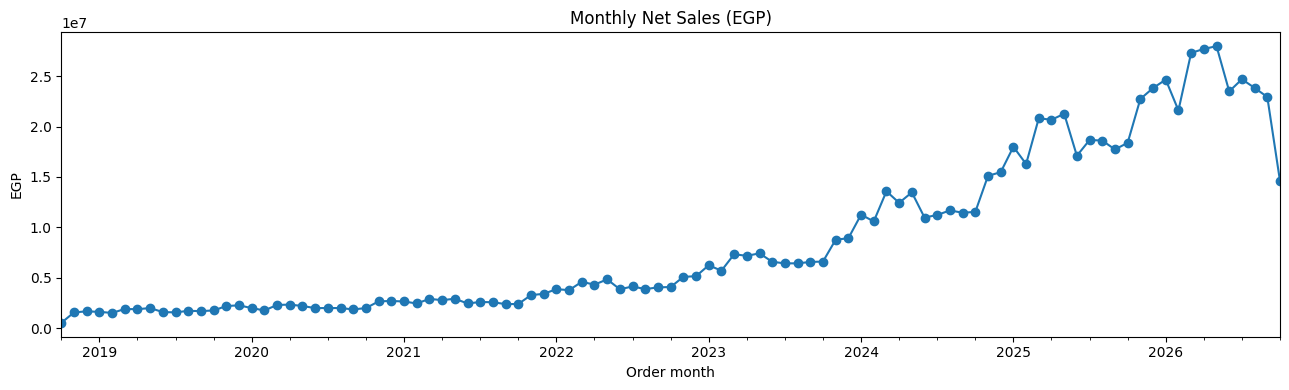

In [16]:
orders_monthly = (orders_clean.dropna(subset=["order_date"])
                  .assign(year_month=lambda x: x["order_date"].dt.to_period("M").dt.to_timestamp())
                  .groupby("year_month", as_index=False)
                  .agg(orders=("sales_order_id", "nunique"),
                       gross_sales_EGP=("gross_EGP", "sum"),
                       net_sales_EGP=("net_before_tax_EGP", "sum"),
                       paid_EGP=("paid_total_EGP", "sum")))
display(orders_monthly.tail(18))
ax = orders_monthly.set_index("year_month")["net_sales_EGP"].plot(
    figsize=(13, 4), title="Monthly Net Sales (EGP)", marker="o"
)
ax.set_xlabel("Order month"); ax.set_ylabel("EGP"); plt.tight_layout(); plt.show()

### 6.2 Branch and product/category performance

In [17]:

# ============================================================
# BRANCH & PRODUCT / CATEGORY PERFORMANCE
# ============================================================

# 1. Branch performance
if "branch_id" in orders_clean.columns:
    branch_sales = (
        orders_clean.groupby("branch_id", as_index=False)
        .agg(
            orders=("sales_order_id", "nunique"),
            net_sales_EGP=("net_before_tax_EGP", "sum"),
            paid_EGP=("paid_total_EGP", "sum")
        )
        .sort_values("net_sales_EGP", ascending=False)
    )

    display(branch_sales.head(20))


# 2. Load product reference tables
products = load_table("products_catalog.csv")
skus = load_table("sku_variants.csv")

# 3. Start with a copy of cleaned sales items
item_product = items_clean.copy()

# 4. Validate required columns
if "sku_id" not in item_product.columns:
    raise KeyError("sku_id is missing from items_clean.")

if "product_id" not in products.columns:
    raise KeyError("product_id is missing from products_catalog.csv.")

if "product_id" not in item_product.columns:

    if not {"sku_id", "product_id"}.issubset(skus.columns):
        raise KeyError(
            "sku_variants.csv must contain sku_id and product_id."
        )

    sku_map = skus[["sku_id", "product_id"]].drop_duplicates()

    if sku_map["sku_id"].duplicated().any():
        raise ValueError(
            "sku_variants contains duplicate sku_id values."
        )

    item_product = item_product.merge(
        sku_map,
        on="sku_id",
        how="left",
        validate="many_to_one"
    )

# 5. Select available product attributes
product_attributes = [
    "product_id",
    "product_name_ar",
    "product_name_en",
    "category_en",
    "listed_price_EGP"
]

product_columns = [
    col for col in product_attributes
    if col in products.columns
]

# Avoid duplicate attribute columns if already present
product_columns = [
    col for col in product_columns
    if col == "product_id" or col not in item_product.columns
]

# 6. Merge product information
item_product = item_product.merge(
    products[product_columns].drop_duplicates("product_id"),
    on="product_id",
    how="left",
    validate="many_to_one"
)

# 7. Report product mapping quality
print("Product mapping results:")
print(f"Sales item rows: {len(item_product):,}")
print(
    "Rows with product_id:",
    f"{item_product['product_id'].notna().sum():,}"
)
print(
    "Rows without product_id:",
    f"{item_product['product_id'].isna().sum():,}"
)

# 8. Category performance
if "category_en" in item_product.columns:

    category_performance = (
        item_product.groupby("category_en", dropna=False)
        .agg(
            units=("quantity", "sum"),
            net_sales_EGP=("net_line_EGP", "sum"),
            margin_EGP=("margin_EGP", "sum")
        )
        .sort_values("net_sales_EGP", ascending=False)
    )

    display(category_performance)

else:
    print("category_en is not available in products_catalog.csv.")
    print("Available product columns:", products.columns.tolist())


,branch_id,orders,net_sales_EGP,paid_EGP
2,BR003,6932,"11,434,150.99","13,034,932.88"
73,BR074,6893,"11,274,021.44","12,852,385.32"
14,BR015,6881,"11,244,325.21","12,818,531.10"
48,BR049,6787,"11,011,002.02","12,552,542.96"
26,BR027,6859,"10,935,666.88","12,466,660.85"
29,BR030,6741,"10,931,944.09","12,462,416.50"
22,BR023,6633,"10,903,469.25","12,429,955.58"
46,BR047,6878,"10,902,863.28","12,429,264.65"
9,BR010,6835,"10,893,340.36","12,418,408.49"
64,BR065,6703,"10,849,999.01","12,368,999.11"


Product mapping results:
Sales item rows: 1,138,536
Rows with product_id: 1,138,536
Rows without product_id: 0


,units,net_sales_EGP,margin_EGP
category_en,,,
Men boxers,381819,"194,199,147.01","74,185,815.69"
Men tops,442948,"164,524,154.46","63,199,254.94"
Socks,911138,"116,179,054.70","44,605,474.49"
Men underwear,189180,"53,063,019.43","20,415,784.39"
Women pajamas,78090,"50,215,875.34","19,243,672.55"
Women tops,339951,"48,536,514.39","18,625,550.50"
Girls pajamas,158994,"38,973,530.49","14,967,186.39"
Boys pajamas,156975,"38,187,460.77","14,666,966.34"
Home textiles,98800,"33,646,539.62","12,831,206.83"


In [18]:

# ============================================================
# PRODUCT PROFITABILITY ANALYSIS
# ============================================================

category_profitability = (
    item_product.groupby("category_en", dropna=False)
    .agg(
        units=("quantity", "sum"),
        net_sales_EGP=("net_line_EGP", "sum"),
        margin_EGP=("margin_EGP", "sum")
    )
    .reset_index()
)

category_profitability["margin_rate_pct"] = (
    category_profitability["margin_EGP"]
    / category_profitability["net_sales_EGP"].replace(0, np.nan)
    * 100
)

display(
    category_profitability.sort_values(
        "margin_rate_pct", ascending=False
    ).round(2)
)

# ============================================================
# BRANCH PERFORMANCE
# ============================================================

branch_performance = (
    orders_clean.groupby("branch_id", as_index=False)
    .agg(
        orders=("sales_order_id", "nunique"),
        net_sales_EGP=("net_before_tax_EGP", "sum"),
        paid_EGP=("paid_total_EGP", "sum")
    )
)

branch_performance["average_order_value_EGP"] = (
    branch_performance["net_sales_EGP"]
    / branch_performance["orders"].replace(0, np.nan)
)

display(
    branch_performance.sort_values(
        "net_sales_EGP", ascending=False
    ).head(20).round(2)
)


,category_en,units,net_sales_EGP,margin_EGP,margin_rate_pct
15,Women underwear,38021,"14,516,810.34","5,595,719.86",38.55
3,Girls underwear,36672,"9,130,896.26","3,514,173.36",38.49
9,Men underwear,189180,"53,063,019.43","20,415,784.39",38.47
8,Men tops,442948,"164,524,154.46","63,199,254.94",38.41
1,Boys pajamas,156975,"38,187,460.77","14,666,966.34",38.41
2,Girls pajamas,158994,"38,973,530.49","14,967,186.39",38.40
10,Socks,911138,"116,179,054.70","44,605,474.49",38.39
14,Women tops,339951,"48,536,514.39","18,625,550.50",38.37
5,Kids underwear,295974,"27,556,267.02","10,573,221.12",38.37
12,Women bras,147080,"32,026,817.00","12,285,514.14",38.36


,branch_id,orders,net_sales_EGP,paid_EGP,average_order_value_EGP
2,BR003,6932,"11,434,150.99","13,034,932.88","1,649.47"
73,BR074,6893,"11,274,021.44","12,852,385.32","1,635.58"
14,BR015,6881,"11,244,325.21","12,818,531.10","1,634.11"
48,BR049,6787,"11,011,002.02","12,552,542.96","1,622.37"
26,BR027,6859,"10,935,666.88","12,466,660.85","1,594.35"
29,BR030,6741,"10,931,944.09","12,462,416.50","1,621.71"
22,BR023,6633,"10,903,469.25","12,429,955.58","1,643.82"
46,BR047,6878,"10,902,863.28","12,429,264.65","1,585.18"
9,BR010,6835,"10,893,340.36","12,418,408.49","1,593.76"
64,BR065,6703,"10,849,999.01","12,368,999.11","1,618.68"


In [19]:

# ============================================================
# BUSINESS INSIGHTS: CATEGORY & BRANCH CONCENTRATION
# ============================================================

# 1. Category contribution
category_insights = category_profitability.copy()

total_category_sales = category_insights["net_sales_EGP"].sum()
total_category_margin = category_insights["margin_EGP"].sum()
total_category_units = category_insights["units"].sum()

category_insights["sales_share_pct"] = (
    category_insights["net_sales_EGP"] / total_category_sales * 100
)

category_insights["margin_share_pct"] = (
    category_insights["margin_EGP"] / total_category_margin * 100
)

category_insights["units_share_pct"] = (
    category_insights["units"] / total_category_units * 100
)

print("CATEGORY CONTRIBUTION")
display(
    category_insights[
        [
            "category_en",
            "sales_share_pct",
            "margin_share_pct",
            "units_share_pct",
            "margin_rate_pct"
        ]
    ]
    .sort_values("sales_share_pct", ascending=False)
    .round(2)
    .reset_index(drop=True)
)

# 2. Branch performance across ALL branches
branch_all = branch_performance.copy()

branch_all["sales_share_pct"] = (
    branch_all["net_sales_EGP"]
    / branch_all["net_sales_EGP"].sum() * 100
)

branch_all["orders_share_pct"] = (
    branch_all["orders"] / branch_all["orders"].sum() * 100
)

print("BRANCH PERFORMANCE SUMMARY")
display(
    branch_all[
        [
            "branch_id",
            "orders",
            "net_sales_EGP",
            "average_order_value_EGP",
            "sales_share_pct"
        ]
    ]
    .sort_values("net_sales_EGP", ascending=False)
    .round(2)
    .reset_index(drop=True)
)

print("BRANCH DISTRIBUTION")

branch_summary = branch_all[
    ["orders", "net_sales_EGP", "average_order_value_EGP"]
].describe().round(2)

display(branch_summary)

print(
    "Number of branches:",
    branch_all["branch_id"].nunique()
)

print(
    "Total branch sales:",
    round(branch_all["net_sales_EGP"].sum(), 2)
)

print(
    "Total branch orders:",
    branch_all["orders"].sum()
)


CATEGORY CONTRIBUTION


,category_en,sales_share_pct,margin_share_pct,units_share_pct,margin_rate_pct
0,Men boxers,23.08,23.00,11.23,38.20
1,Men tops,19.56,19.59,13.03,38.41
2,Socks,13.81,13.83,26.81,38.39
3,Men underwear,6.31,6.33,5.57,38.47
4,Women pajamas,5.97,5.97,2.30,38.32
5,Women tops,5.77,5.77,10.00,38.37
6,Girls pajamas,4.63,4.64,4.68,38.40
7,Boys pajamas,4.54,4.55,4.62,38.41
8,Home textiles,4.00,3.98,2.91,38.14
9,Women bras,3.81,3.81,4.33,38.36


BRANCH PERFORMANCE SUMMARY


,branch_id,orders,net_sales_EGP,average_order_value_EGP,sales_share_pct
0,BR003,6932,"11,434,150.99","1,649.47",1.36
1,BR074,6893,"11,274,021.44","1,635.58",1.34
2,BR015,6881,"11,244,325.21","1,634.11",1.34
3,BR049,6787,"11,011,002.02","1,622.37",1.31
4,BR027,6859,"10,935,666.88","1,594.35",1.30
5,BR030,6741,"10,931,944.09","1,621.71",1.30
6,BR023,6633,"10,903,469.25","1,643.82",1.30
7,BR047,6878,"10,902,863.28","1,585.18",1.30
8,BR010,6835,"10,893,340.36","1,593.76",1.29
9,BR065,6703,"10,849,999.01","1,618.68",1.29


BRANCH DISTRIBUTION


,orders,net_sales_EGP,average_order_value_EGP
count,80.00,80.00,80.00
mean,"6,750.00","10,515,927.20","1,557.93"
std,84.64,"318,443.03",43.22
min,"6,572.00","9,844,120.95","1,457.74"
25%,"6,679.75","10,274,696.81","1,526.91"
50%,"6,752.00","10,524,582.54","1,559.07"
75%,"6,819.75","10,733,956.57","1,586.37"
max,"6,952.00","11,434,150.99","1,649.47"


Number of branches: 80
Total branch sales: 841274176.32
Total branch orders: 540000


In [20]:

# ============================================================
# SALES TIME-SERIES ANALYSIS
# Monthly Trends, Annual Performance & Seasonality
# ============================================================

import pandas as pd
import numpy as np
import calendar

# 1. Detect the order date column
date_candidates = [
    "order_date",
    "sales_order_date",
    "created_at",
    "order_datetime"
]

date_col = next(
    (col for col in date_candidates if col in orders_clean.columns),
    None
)

if date_col is None:
    raise KeyError(
        "No recognized order date column found. "
        f"Available columns: {orders_clean.columns.tolist()}"
    )

if "net_before_tax_EGP" not in orders_clean.columns:
    raise KeyError("net_before_tax_EGP is missing from orders_clean.")

# 2. Prepare a separate analysis copy
sales_time = orders_clean.copy()

sales_time[date_col] = pd.to_datetime(
    sales_time[date_col], errors="coerce"
)

sales_time = sales_time.dropna(subset=[date_col]).copy()

sales_time["year_month"] = (
    sales_time[date_col].dt.to_period("M")
)

sales_time["year"] = sales_time[date_col].dt.year
sales_time["month_number"] = sales_time[date_col].dt.month

min_date = sales_time[date_col].min()
max_date = sales_time[date_col].max()

print("ANALYSIS PERIOD")
print("Start:", min_date)
print("End:", max_date)
print("Valid dated orders:", f"{len(sales_time):,}")

# 3. Monthly sales performance
monthly_sales = (
    sales_time.groupby("year_month")
    .agg(
        orders=("sales_order_id", "nunique"),
        net_sales_EGP=("net_before_tax_EGP", "sum")
    )
    .reset_index()
)

monthly_sales["month_start"] = (
    monthly_sales["year_month"].dt.to_timestamp()
)

monthly_sales = monthly_sales.sort_values("month_start")

# Identify complete calendar months
monthly_sales["month_end"] = (
    monthly_sales["month_start"] + pd.offsets.MonthEnd(0)
)

monthly_sales["is_complete_month"] = (
    (monthly_sales["month_start"] >= min_date.to_period("M").to_timestamp())
    & (monthly_sales["month_start"] <= max_date.to_period("M").to_timestamp())
    & (monthly_sales["month_start"] != min_date.to_period("M").to_timestamp()
       if min_date.day > 1 else True)
    & (monthly_sales["month_end"] <= max_date)
)

print("\nMONTHLY SALES - LATEST 15 MONTHS")
display(
    monthly_sales.tail(15)[
        ["month_start", "orders", "net_sales_EGP", "is_complete_month"]
    ].round(2)
)

# 4. Annual sales performance
yearly_sales = (
    sales_time.groupby("year")
    .agg(
        orders=("sales_order_id", "nunique"),
        net_sales_EGP=("net_before_tax_EGP", "sum"),
        first_order_date=(date_col, "min"),
        last_order_date=(date_col, "max"),
        active_months=("year_month", "nunique")
    )
    .reset_index()
)

yearly_sales["is_full_calendar_year"] = (
    (yearly_sales["first_order_date"].dt.month == 1)
    & (yearly_sales["first_order_date"].dt.day == 1)
    & (yearly_sales["last_order_date"].dt.month == 12)
    & (yearly_sales["last_order_date"].dt.day == 31)
)

print("\nANNUAL SALES PERFORMANCE")
display(yearly_sales.round(2))

# 5. Calendar-month seasonality
complete_months = monthly_sales[
    monthly_sales["is_complete_month"]
].copy()

complete_months["calendar_month"] = (
    complete_months["month_start"].dt.month
)

seasonality = (
    complete_months.groupby("calendar_month")
    .agg(
        observed_months=("net_sales_EGP", "count"),
        average_monthly_sales_EGP=("net_sales_EGP", "mean"),
        median_monthly_sales_EGP=("net_sales_EGP", "median"),
        average_orders=("orders", "mean")
    )
    .reset_index()
)

seasonality["month_name"] = seasonality["calendar_month"].apply(
    lambda x: calendar.month_abbr[x]
)

seasonality = seasonality.sort_values(
    "average_monthly_sales_EGP", ascending=False
)

print("\nSEASONALITY BY CALENDAR MONTH")
display(seasonality.round(2))

# 6. Top and bottom complete months
print("\nTOP 10 COMPLETE MONTHS")
display(
    complete_months.nlargest(10, "net_sales_EGP")[
        ["month_start", "orders", "net_sales_EGP"]
    ].round(2)
)

print("\nBOTTOM 10 COMPLETE MONTHS")
display(
    complete_months.nsmallest(10, "net_sales_EGP")[
        ["month_start", "orders", "net_sales_EGP"]
    ].round(2)
)


ANALYSIS PERIOD
Start: 2018-10-19 00:00:00
End: 2026-10-18 00:00:00
Valid dated orders: 540,000

MONTHLY SALES - LATEST 15 MONTHS


,month_start,orders,net_sales_EGP,is_complete_month
82,2025-08-01,7140,"18,612,020.89",True
83,2025-09-01,7177,"17,731,272.11",True
84,2025-10-01,7253,"18,390,022.72",True
85,2025-11-01,9428,"22,740,268.37",True
86,2025-12-01,9608,"23,828,040.13",True
87,2026-01-01,7971,"24,661,715.93",True
88,2026-02-01,7124,"21,608,269.85",True
89,2026-03-01,9021,"27,313,076.89",True
90,2026-04-01,8871,"27,707,827.21",True
91,2026-05-01,9142,"27,982,810.87",True



ANNUAL SALES PERFORMANCE


,year,orders,net_sales_EGP,first_order_date,last_order_date,active_months,is_full_calendar_year
0,2018,8576,"3,734,869.34",2018-10-19,2018-12-31,3,False
1,2019,44108,"21,620,204.92",2019-01-01,2019-12-31,12,True
2,2020,46425,"25,709,342.33",2020-01-01,2020-12-31,12,True
3,2021,53269,"32,716,862.22",2021-01-01,2021-12-31,12,True
4,2022,61934,"51,578,474.33",2022-01-01,2022-12-31,12,True
5,2023,72233,"84,147,934.73",2023-01-01,2023-12-31,12,True
6,2024,81885,"148,782,350.27",2024-01-01,2024-12-31,12,True
7,2025,93384,"234,138,548.44",2025-01-01,2025-12-31,12,True
8,2026,78186,"238,845,589.74",2026-01-01,2026-10-18,10,False



SEASONALITY BY CALENDAR MONTH


,calendar_month,observed_months,average_monthly_sales_EGP,median_monthly_sales_EGP,average_orders,month_name
4,5,8,"10,259,870.82","6,126,913.01","6,202.50",May
2,3,8,"10,090,846.10","5,959,480.58","6,173.38",Mar
3,4,8,"9,910,584.25","5,743,433.85","5,993.75",Apr
6,7,8,"8,912,171.67","5,276,934.38","5,392.50",Jul
7,8,8,"8,837,278.64","5,149,506.61","5,380.25",Aug
0,1,8,"8,781,474.63","5,050,520.10","5,343.25",Jan
8,9,8,"8,580,830.75","5,301,553.82","5,244.50",Sep
5,6,8,"8,502,444.64","5,218,591.06","5,217.12",Jun
1,2,8,"7,956,033.04","4,730,823.64","4,928.62",Feb
11,12,8,"7,923,540.72","4,275,827.82","6,319.38",Dec



TOP 10 COMPLETE MONTHS


,month_start,orders,net_sales_EGP
91,2026-05-01,9142,"27,982,810.87"
90,2026-04-01,8871,"27,707,827.21"
89,2026-03-01,9021,"27,313,076.89"
93,2026-07-01,8124,"24,699,598.17"
87,2026-01-01,7971,"24,661,715.93"
94,2026-08-01,7983,"23,840,700.90"
86,2025-12-01,9608,"23,828,040.13"
92,2026-06-01,7748,"23,495,284.72"
95,2026-09-01,7561,"22,941,492.26"
85,2025-11-01,9428,"22,740,268.37"



BOTTOM 10 COMPLETE MONTHS


,month_start,orders,net_sales_EGP
4,2019-02-01,3141,"1,505,380.47"
1,2018-11-01,3701,"1,555,383.91"
9,2019-07-01,3375,"1,560,442.50"
8,2019-06-01,3242,"1,586,648.28"
3,2019-01-01,3387,"1,611,424.47"
2,2018-12-01,3740,"1,662,934.74"
11,2019-09-01,3389,"1,686,672.49"
10,2019-08-01,3454,"1,712,210.33"
12,2019-10-01,3417,"1,750,049.91"
16,2020-02-01,3280,"1,753,361.57"


In [21]:

# ============================================================
# NORMALIZED SEASONALITY & YEAR-OVER-YEAR GROWTH
# ============================================================

# 1. Use complete calendar years only for seasonality
full_years = yearly_sales.loc[
    yearly_sales["is_full_calendar_year"], "year"
].tolist()

seasonal_data = monthly_sales.copy()

seasonal_data["year"] = seasonal_data["month_start"].dt.year
seasonal_data["month_number"] = seasonal_data["month_start"].dt.month

seasonal_data = seasonal_data[
    (seasonal_data["year"].isin(full_years))
    & (seasonal_data["is_complete_month"])
].copy()

# 2. Calculate each year's average monthly revenue
seasonal_data["year_average_sales"] = (
    seasonal_data.groupby("year")["net_sales_EGP"]
    .transform("mean")
)

# Index = 100 means equal to that year's monthly average
seasonal_data["seasonality_index"] = (
    seasonal_data["net_sales_EGP"]
    / seasonal_data["year_average_sales"] * 100
)

seasonal_data["month_name"] = (
    seasonal_data["month_number"].apply(
        lambda x: calendar.month_abbr[x]
    )
)

seasonality_index = (
    seasonal_data.groupby("month_number")
    .agg(
        observed_years=("seasonality_index", "count"),
        average_index=("seasonality_index", "mean"),
        median_index=("seasonality_index", "median")
    )
    .reset_index()
)

seasonality_index["month_name"] = (
    seasonality_index["month_number"].apply(
        lambda x: calendar.month_abbr[x]
    )
)

seasonality_index = seasonality_index.sort_values(
    "month_number"
)

print("NORMALIZED SEASONALITY INDEX")
display(seasonality_index.round(2))

# 3. Monthly YoY comparison: 2025 vs 2024
monthly_yoy = monthly_sales.copy()
monthly_yoy["year"] = monthly_yoy["month_start"].dt.year
monthly_yoy["month_number"] = monthly_yoy["month_start"].dt.month

comparison_2024_2025 = (
    monthly_yoy[
        monthly_yoy["year"].isin([2024, 2025])
    ]
    .pivot(
        index="month_number",
        columns="year",
        values=["net_sales_EGP", "orders"]
    )
)

comparison_2024_2025.columns = [
    f"{metric}_{year}"
    for metric, year in comparison_2024_2025.columns
]

comparison_2024_2025 = comparison_2024_2025.reset_index()

comparison_2024_2025["sales_growth_pct"] = (
    comparison_2024_2025["net_sales_EGP_2025"]
    / comparison_2024_2025["net_sales_EGP_2024"] - 1
) * 100

comparison_2024_2025["orders_growth_pct"] = (
    comparison_2024_2025["orders_2025"]
    / comparison_2024_2025["orders_2024"] - 1
) * 100

comparison_2024_2025["month_name"] = (
    comparison_2024_2025["month_number"].apply(
        lambda x: calendar.month_abbr[x]
    )
)

print("\nMONTHLY YOY: 2025 VS 2024")
display(
    comparison_2024_2025[
        [
            "month_name",
            "net_sales_EGP_2024",
            "net_sales_EGP_2025",
            "sales_growth_pct",
            "orders_growth_pct"
        ]
    ].round(2)
)

# 4. Jan-Sep 2026 vs Jan-Sep 2025
comparison_period = monthly_yoy[
    monthly_yoy["month_number"].between(1, 9)
    & monthly_yoy["year"].isin([2025, 2026])
]

period_summary = (
    comparison_period.groupby("year")
    .agg(
        orders=("orders", "sum"),
        net_sales_EGP=("net_sales_EGP", "sum")
    )
)

period_summary["average_order_value_EGP"] = (
    period_summary["net_sales_EGP"]
    / period_summary["orders"]
)

print("\nJAN-SEP COMPARISON")
display(period_summary.round(2))

if 2025 in period_summary.index and 2026 in period_summary.index:

    sales_growth = (
        period_summary.loc[2026, "net_sales_EGP"]
        / period_summary.loc[2025, "net_sales_EGP"] - 1
    ) * 100

    orders_growth = (
        period_summary.loc[2026, "orders"]
        / period_summary.loc[2025, "orders"] - 1
    ) * 100

    aov_growth = (
        period_summary.loc[2026, "average_order_value_EGP"]
        / period_summary.loc[2025, "average_order_value_EGP"] - 1
    ) * 100

    print(f"Jan-Sep Sales Growth: {sales_growth:.2f}%")
    print(f"Jan-Sep Orders Growth: {orders_growth:.2f}%")
    print(f"Jan-Sep AOV Growth: {aov_growth:.2f}%")


NORMALIZED SEASONALITY INDEX


,month_number,observed_years,average_index,median_index,month_name
0,1,7,91.53,90.81,Jan
1,2,7,84.68,83.55,Feb
2,3,7,106.58,106.75,Mar
3,4,7,103.37,102.30,Apr
4,5,7,107.95,108.65,May
5,6,7,89.99,89.64,Jun
6,7,7,92.66,93.02,Jul
7,8,7,93.32,94.15,Aug
8,9,7,91.18,92.35,Sep
9,10,7,93.43,94.21,Oct



MONTHLY YOY: 2025 VS 2024


,month_name,net_sales_EGP_2024,net_sales_EGP_2025,sales_growth_pct,orders_growth_pct
0,Jan,"11,258,765.30","17,995,720.47",59.84,15.53
1,Feb,"10,590,027.94","16,286,442.84",53.79,9.13
2,Mar,"13,578,855.91","20,829,089.36",53.39,15.98
3,Apr,"12,433,530.67","20,674,955.71",66.28,17.75
4,May,"13,470,826.15","21,274,710.19",57.93,14.22
5,Jun,"10,970,962.25","17,103,462.53",55.90,10.60
6,Jul,"11,228,279.34","18,672,543.12",66.30,16.77
7,Aug,"11,680,153.26","18,612,020.89",59.35,11.35
8,Sep,"11,449,794.00","17,731,272.11",54.86,14.08
9,Oct,"11,533,613.41","18,390,022.72",59.45,14.69



JAN-SEP COMPARISON


,orders,net_sales_EGP,average_order_value_EGP
year,,,
2025,67095,"169,180,217.22","2,521.50"
2026,73545,"224,250,776.80","3,049.16"


Jan-Sep Sales Growth: 32.55%
Jan-Sep Orders Growth: 9.61%
Jan-Sep AOV Growth: 20.93%


### 6.3 Marketing campaign descriptive review
Campaign-level spend, budget, impressions, clicks and available outcomes are descriptive indicators. Without a reliable order-to-campaign key, do not interpret them as causal attribution.

In [22]:
campaigns = load_table("marketing_campaigns.csv")
display(campaigns.head())
campaign_numeric = [c for c in campaigns.select_dtypes(include=np.number).columns]
display(campaigns[campaign_numeric].describe().T if campaign_numeric else pd.DataFrame())
if {"spend_EGP", "budget_EGP"}.issubset(campaigns.columns):
    campaigns["budget_utilization_pct"] = np.where(
        campaigns["budget_EGP"] > 0, campaigns["spend_EGP"] / campaigns["budget_EGP"] * 100, np.nan
    )
    display(campaigns[["campaign_id", "budget_EGP", "spend_EGP", "budget_utilization_pct"]]
            .sort_values("spend_EGP", ascending=False).head(15))

,campaign_id,start_date,end_date,channel,target_audience,governorate_ar,budget_EGP,spend_EGP,impressions,clicks,orders_attributed
0,MKT00001,2026-10-14,2026-10-18,Meta Ads,Men,مطروح,161471,"127,561.63",5549655,275741,12326
1,MKT00002,2018-10-22,2018-11-10,Outdoor,Kids,بورسعيد,48867,"34,420.78",3086709,194598,1644
2,MKT00003,2021-04-14,2021-06-09,Meta Ads,Kids,مطروح,190681,"129,339.53",5447045,387692,18064
3,MKT00004,2020-05-27,2020-07-03,In-store,Women,الإسكندرية,225004,"172,433.63",9639206,765815,22649
4,MKT00005,2021-11-05,2021-12-30,Influencers,Men,مطروح,86691,"69,873.13",4825110,350546,29029


,count,mean,std,min,25%,50%,75%,max
budget_EGP,"2,200.00","124,809.52","71,251.18","1,004.00","62,348.75","122,913.00","187,688.00","249,859.00"
spend_EGP,"2,200.00","99,776.87","58,772.22",825.30,"49,633.64","97,956.19","144,688.16","244,929.22"
impressions,"2,200.00","4,887,413.84","3,855,589.10","11,776.00","1,804,306.75","3,821,401.00","7,245,758.75","19,787,869.00"
clicks,"2,200.00","218,004.57","219,834.26",695.00,"59,197.50","142,893.50","307,173.50","1,550,082.00"
orders_attributed,"2,200.00","10,957.61","14,054.66",10.00,"1,993.25","5,550.00","14,123.50","138,616.00"


,campaign_id,budget_EGP,spend_EGP,budget_utilization_pct
1679,MKT01680,246216,"244,929.22",99.48
1896,MKT01897,243316,"242,711.58",99.75
1377,MKT01378,241508,"239,805.34",99.29
108,MKT00109,240968,"239,573.63",99.42
1123,MKT01124,240413,"239,457.62",99.60
535,MKT00536,244871,"239,189.77",97.68
98,MKT00099,237315,"236,369.02",99.60
1763,MKT01764,246755,"235,330.00",95.37
202,MKT00203,249315,"235,159.84",94.32
97,MKT00098,239918,"234,305.47",97.66


## 7. Advanced analytics aligned with the current Cottonil application

### 7.1 Customer Win-Back / RFM segmentation
RFM is computed only for orders with a valid customer ID. The recency reference date is one day after the latest observed order date. Scores are relative quintiles within this dataset, not permanent customer labels.

In [23]:
rfm_orders = orders_clean.dropna(subset=["customer_id_clean", "order_date"]).copy()
rfm_orders = rfm_orders[rfm_orders["customer_id_clean"].ne("")]
reference_date = rfm_orders["order_date"].max() + pd.Timedelta(days=1)
rfm = (rfm_orders.groupby("customer_id_clean")
       .agg(Recency=("order_date", lambda s: (reference_date - s.max()).days),
            Frequency=("sales_order_id", "nunique"),
            Monetary=("paid_total_EGP", "sum"))
       .reset_index())
def quintile_score(series, ascending=True):
    # rank(method='first') avoids qcut failures when values repeat heavily
    ranks = series.rank(method="first", ascending=ascending)
    return pd.qcut(ranks, 5, labels=[1, 2, 3, 4, 5]).astype(int)

if len(rfm) >= 5:
    rfm["R_score"] = quintile_score(rfm["Recency"], ascending=False)
    rfm["F_score"] = quintile_score(rfm["Frequency"], ascending=True)
    rfm["M_score"] = quintile_score(rfm["Monetary"], ascending=True)
    rfm["RFM_score"] = rfm[["R_score", "F_score", "M_score"]].sum(axis=1)
    rfm["segment"] = np.select(
        [rfm["RFM_score"] >= 13, rfm["RFM_score"] >= 10,
         rfm["RFM_score"] >= 7, rfm["RFM_score"] >= 5],
        ["Champions / high value", "Loyal / promising", "Needs attention", "At risk"],
        default="Low engagement"
    )
    display(rfm.groupby("segment").agg(
        customers=("customer_id_clean", "nunique"),
        avg_recency_days=("Recency", "mean"),
        avg_frequency=("Frequency", "mean"),
        total_monetary_EGP=("Monetary", "sum")
    ).sort_values("customers", ascending=False))
else:
    print("Not enough identified customers to create quintile-based RFM scores.")
print("Identified customers used for RFM:", rfm["customer_id_clean"].nunique())
print("Orders excluded from customer-level RFM due to missing customer ID:",
      int(orders_clean["customer_id_clean"].isna().sum()))

,customers,avg_recency_days,avg_frequency,total_monetary_EGP
segment,,,,
Loyal / promising,22784,231.46,7.58,"322,128,491.92"
Needs attention,22604,325.50,4.32,"154,538,967.86"
Champions / high value,11398,92.71,11.11,"250,523,524.35"
At risk,10935,436.07,2.59,"36,354,736.78"
Low engagement,6939,711.88,1.67,"12,020,437.36"


Identified customers used for RFM: 74660
Orders excluded from customer-level RFM due to missing customer ID: 102961


### 7.2 AI Demand & Inventory Intelligence — monthly demand forecast
The workflow mirrors the current app's methodology: monthly unit demand, continuous month index, calendar/lag/rolling features, Random Forest, six most recent one-step-ahead validation months, and a seasonal-naive lag-12 benchmark. Forecasting is run per product category only when at least 30 monthly observations exist. Results should be compared with the app output after execution.

In [24]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Build category-level monthly demand from line items joined to product categories.
if "category_en" not in item_product.columns:
    raise KeyError("category_en is required for category-level demand forecasting.")
demand = item_product.dropna(subset=["order_date"]).copy()
demand["month"] = demand["order_date"].dt.to_period("M").dt.to_timestamp()
monthly_demand = (demand.groupby(["category_en", "month"])["quantity"]
                  .sum().rename("units").reset_index())

FORECAST_FEATURES = [
    "month_sin", "month_cos", "time_index",
    "lag_1", "lag_2", "lag_3", "lag_6", "lag_12",
    "rolling_mean_3", "rolling_mean_6", "rolling_mean_12",
]

def make_features(history, target_date, time_index):
    h = np.asarray(history, dtype=float)
    return {
        "month_sin": np.sin(2 * np.pi * target_date.month / 12),
        "month_cos": np.cos(2 * np.pi * target_date.month / 12),
        "time_index": float(time_index),
        "lag_1": float(h[-1]), "lag_2": float(h[-2]),
        "lag_3": float(h[-3]), "lag_6": float(h[-6]),
        "lag_12": float(h[-12]),
        "rolling_mean_3": float(np.mean(h[-3:])),
        "rolling_mean_6": float(np.mean(h[-6:])),
        "rolling_mean_12": float(np.mean(h[-12:])),
    }

def forecast_category(series, horizon=3):
    y = pd.to_numeric(series, errors="coerce").astype(float).clip(lower=0).dropna()
    y.index = pd.to_datetime(y.index).to_period("M").to_timestamp()
    y = y.groupby(level=0).sum().sort_index()
    if len(y) < 30:
        return None, {"status": "Skipped: fewer than 30 months", "months": len(y)}
    full_index = pd.date_range(y.index.min(), y.index.max(), freq="MS")
    y = y.reindex(full_index, fill_value=0.0)
    values = y.to_numpy()
    X, target = [], []
    for i in range(12, len(values)):
        X.append(make_features(values[:i], full_index[i], i))
        target.append(values[i])
    X_all = pd.DataFrame(X, columns=FORECAST_FEATURES)
    y_all = np.asarray(target, dtype=float)

    actual, predicted, naive = [], [], []
    for pos in range(max(24, len(values) - 6), len(values)):
        train_end = pos - 12
        if train_end < 12:
            continue
        model = RandomForestRegressor(
            n_estimators=220, max_depth=7, min_samples_leaf=2,
            max_features=0.9, random_state=42, n_jobs=-1
        )
        model.fit(X_all.iloc[:train_end], y_all[:train_end])
        x_test = pd.DataFrame([make_features(values[:pos], full_index[pos], pos)])
        predicted.append(max(0.0, float(model.predict(x_test)[0])))
        actual.append(float(values[pos]))
        naive.append(float(values[pos - 12]))
    if len(actual) < 3:
        return None, {"status": "Skipped: insufficient backtest points", "months": len(y)}
    actual_arr, pred_arr, naive_arr = map(np.asarray, (actual, predicted, naive))
    denom = np.abs(actual_arr).sum()
    metrics = {
        "status": "Evaluated", "months": len(y), "backtest_months": len(actual),
        "RF_MAE": mean_absolute_error(actual_arr, pred_arr),
        "RF_WAPE_pct": np.abs(actual_arr - pred_arr).sum() / denom * 100 if denom else np.nan,
        "Seasonal_Naive_WAPE_pct": np.abs(actual_arr - naive_arr).sum() / denom * 100 if denom else np.nan,
    }
    final_model = RandomForestRegressor(
        n_estimators=220, max_depth=7, min_samples_leaf=2,
        max_features=0.9, random_state=42, n_jobs=-1
    )
    final_model.fit(X_all, y_all)
    future_dates = pd.date_range(full_index[-1] + pd.offsets.MonthBegin(1), periods=horizon, freq="MS")
    history = list(values)
    future = []
    for step, date in enumerate(future_dates):
        pred = max(0.0, float(final_model.predict(
            pd.DataFrame([make_features(history, date, len(values) + step)])
        )[0]))
        future.append(pred)
        history.append(pred)
    return pd.DataFrame({"month": future_dates, "forecast_units": future}), metrics

forecast_outputs, forecast_metrics = [], []
for category, group in monthly_demand.groupby("category_en"):
    series = group.set_index("month")["units"]
    forecast_df, metrics = forecast_category(series, horizon=3)
    metrics["category_en"] = category
    forecast_metrics.append(metrics)
    if forecast_df is not None:
        forecast_df["category_en"] = category
        forecast_outputs.append(forecast_df)

forecast_metrics_df = pd.DataFrame(forecast_metrics)
display(forecast_metrics_df.sort_values("RF_WAPE_pct", na_position="last"))
forecast_table = pd.concat(forecast_outputs, ignore_index=True) if forecast_outputs else pd.DataFrame()
display(forecast_table.head(30))

,status,months,backtest_months,RF_MAE,RF_WAPE_pct,Seasonal_Naive_WAPE_pct,category_en
11,Evaluated,97,6,35.29,10.22,16.36,Women bottoms
14,Evaluated,97,6,487.49,10.36,13.96,Women tops
8,Evaluated,97,6,641.82,10.43,12.66,Men tops
13,Evaluated,97,6,131.67,12.13,10.08,Women pajamas
1,Evaluated,97,6,258.87,12.14,14.46,Boys pajamas
3,Evaluated,97,6,58.34,12.93,18.83,Girls underwear
10,Evaluated,97,6,"1,677.10",13.18,13.61,Socks
7,Evaluated,97,6,773.47,14.77,11.77,Men boxers
2,Evaluated,97,6,324.96,14.83,11.68,Girls pajamas
9,Evaluated,97,6,391.69,14.83,14.02,Men underwear


,month,forecast_units,category_en
0,2026-11-01,363.61,Accessories
1,2026-12-01,374.62,Accessories
2,2027-01-01,354.42,Accessories
3,2026-11-01,"2,224.56",Boys pajamas
4,2026-12-01,"2,375.70",Boys pajamas
5,2027-01-01,"2,402.04",Boys pajamas
6,2026-11-01,"2,498.62",Girls pajamas
7,2026-12-01,"2,647.94",Girls pajamas
8,2027-01-01,"2,625.11",Girls pajamas
9,2026-11-01,506.37,Girls underwear


### 7.3 Pricing & Margin What-If Model
A scenario calculator can quantify the arithmetic impact of price/discount/cost changes using observed line-level quantities and costs. It is not an elasticity model and does not estimate customer response or causal demand changes.

In [25]:
pricing_base = items_clean.copy()
pricing_base["quantity"] = pd.to_numeric(pricing_base["quantity"], errors="coerce")
pricing_base["unit_price_EGP"] = pd.to_numeric(pricing_base["unit_price_EGP"], errors="coerce")
pricing_base["unit_cost_EGP"] = pd.to_numeric(pricing_base["unit_cost_EGP"], errors="coerce")
pricing_base = pricing_base.dropna(subset=["quantity", "unit_price_EGP", "unit_cost_EGP"])
pricing_base = pricing_base[(pricing_base["quantity"] > 0) & (pricing_base["unit_price_EGP"] >= 0)]
base_units = pricing_base["quantity"].sum()
base_revenue = (pricing_base["quantity"] * pricing_base["unit_price_EGP"]).sum()
base_cost = (pricing_base["quantity"] * pricing_base["unit_cost_EGP"]).sum()
scenarios = []
for price_change_pct, discount_change_pct, cost_change_pct in [
    (0, 0, 0), (5, 0, 0), (-5, 0, 0), (0, 2, 0), (0, 0, 5), (5, 1, -3)
]:
    scenario_price = pricing_base["unit_price_EGP"] * (1 + price_change_pct / 100)
    scenario_discount = np.maximum(0, scenario_price * discount_change_pct / 100)
    scenario_revenue = ((scenario_price - scenario_discount) * pricing_base["quantity"]).sum()
    scenario_cost = (pricing_base["unit_cost_EGP"] * (1 + cost_change_pct / 100) * pricing_base["quantity"]).sum()
    scenario_profit = scenario_revenue - scenario_cost
    scenarios.append({
        "price_change_pct": price_change_pct,
        "discount_pct_of_scenario_price": discount_change_pct,
        "unit_cost_change_pct": cost_change_pct,
        "scenario_revenue_EGP": scenario_revenue,
        "scenario_cost_EGP": scenario_cost,
        "scenario_gross_profit_EGP": scenario_profit,
        "scenario_margin_pct": scenario_profit / scenario_revenue * 100 if scenario_revenue else np.nan,
    })
pricing_scenarios = pd.DataFrame(scenarios)
display(pricing_scenarios)

,price_change_pct,discount_pct_of_scenario_price,unit_cost_change_pct,scenario_revenue_EGP,scenario_cost_EGP,scenario_gross_profit_EGP,scenario_margin_pct
0,0,0,0,"879,195,776.55","518,715,876.82","360,479,899.73",41.00
1,5,0,0,"923,155,565.38","518,715,876.82","404,439,688.56",43.81
2,-5,0,0,"835,235,987.72","518,715,876.82","316,520,110.90",37.90
3,0,2,0,"861,611,861.02","518,715,876.82","342,895,984.20",39.80
4,0,0,5,"879,195,776.55","544,651,670.66","334,544,105.89",38.05
5,5,1,-3,"913,924,009.72","503,154,400.52","410,769,609.21",44.95


### 7.4 Warehouse-to-Branch Allocation Plan
The stock table is aggregated at its documented business grain. Do not treat category/location monthly stock as SKU-level stock. The following is a diagnostic view of stock by location/category; any allocation recommendation must respect transfer direction and operational constraints.

In [26]:
stock_view = stock.copy()
if "year_month" in stock_view:
    stock_view["year_month"] = pd.to_datetime(stock_view["year_month"], errors="coerce")
if "year_month" in stock_view and stock_view["year_month"].notna().any():
    latest_stock_month = stock_view["year_month"].max()
    latest_stock = stock_view[stock_view["year_month"].eq(latest_stock_month)].copy()
    print("Latest stock snapshot:", latest_stock_month)
else:
    latest_stock = stock_view.copy()
display(latest_stock.head())
stock_group_cols = [c for c in ["stock_location_type", "stock_location_id", "product_category"] if c in latest_stock]
stock_measure = next((c for c in ["closing_stock_units", "stock_units", "quantity", "on_hand_units"] if c in latest_stock), None)
if stock_group_cols and stock_measure:
    display(latest_stock.groupby(stock_group_cols, dropna=False)[stock_measure].sum().reset_index()
            .sort_values(stock_measure, ascending=False))
print("Transfer columns:", transfers.columns.tolist())
print("Transfer item columns:", transfer_items.columns.tolist())

Latest stock snapshot: 2026-10-01 00:00:00


,year_month,stock_location_id,stock_location_type,product_category,closing_units,closing_stock_value_EGP,stockout_risk_score
141312,2026-10-01,BR001,Branch,Accessories,340,"108,800.00",0.10
141313,2026-10-01,BR001,Branch,Boys pajamas,166,"38,346.00",0.47
141314,2026-10-01,BR001,Branch,Girls pajamas,408,"71,808.00",0.12
141315,2026-10-01,BR001,Branch,Girls underwear,207,"54,027.00",0.26
141316,2026-10-01,BR001,Branch,Home textiles,77,"5,852.00",0.24


Transfer columns: ['transfer_id', 'transfer_date', 'source_warehouse_id', 'destination_branch_id', 'transfer_status', 'transport_cost_EGP']
Transfer item columns: ['transfer_line_id', 'transfer_id', 'sku_id', 'quantity_units']


### 7.5 High-Value Refund Statistical Review
Flag unusually large refunds for review using a robust IQR threshold. A statistical flag is not proof of fraud or error. Return records alone do not prove that returned goods were received back into inventory.

In [27]:
refund_review = returns_clean.copy()
refund_review["refund_amount_EGP"] = pd.to_numeric(refund_review["refund_amount_EGP"], errors="coerce")
refund_values = refund_review["refund_amount_EGP"].dropna()
if len(refund_values):
    q1, q3 = refund_values.quantile([0.25, 0.75])
    iqr = q3 - q1
    upper_fence = q3 + 1.5 * iqr
    refund_review["high_value_flag"] = refund_review["refund_amount_EGP"] > upper_fence
    print("IQR upper fence (EGP):", round(upper_fence, 2))
    display(refund_review[refund_review["high_value_flag"]]
            .sort_values("refund_amount_EGP", ascending=False).head(25))
    display(refund_review.groupby("reason", dropna=False).agg(
        return_records=("return_id", "count"),
        total_refund_EGP=("refund_amount_EGP", "sum"),
        median_refund_EGP=("refund_amount_EGP", "median"),
        high_value_records=("high_value_flag", "sum")
    ).sort_values("total_refund_EGP", ascending=False))

IQR upper fence (EGP): 1037.68


,return_id,sales_order_id,sales_line_id,return_date,sku_id,return_quantity,refund_amount_EGP,reason,refund_method,high_value_flag
25735,RET0025736,SO00531330,SL001120149,2026-09-24,SKU000296,27,"55,679.79",Defect claim,Wallet,True
1790,RET0001791,SO00516794,SL001089592,2026-08-05,SKU000298,18,"39,530.77",Other,Wallet,True
6725,RET0006726,SO00465844,SL000982115,2026-01-27,SKU000607,26,"32,008.72",Other,Cash,True
15275,RET0015276,SO00379533,SL000800168,2025-02-26,SKU000423,41,"31,808.79",Exchange,Cash,True
11037,RET0011038,SO00396793,SL000836483,2025-05-02,SKU000599,52,"30,945.14",Other,Card reversal,True
27005,RET0027006,SO00520961,SL001098273,2026-08-22,SKU000296,14,"30,840.79",Wrong item,Cash,True
25366,RET0025367,SO00469256,SL000989376,2026-02-09,SKU000298,15,"29,869.43",Other,Card reversal,True
7544,RET0007545,SO00481216,SL001014741,2026-03-22,SKU000515,43,"27,068.80",Wrong item,Wallet,True
2378,RET0002379,SO00474155,SL000999750,2026-03-02,SKU000296,11,"25,006.45",Defect claim,Cash,True
20947,RET0020948,SO00421916,SL000889681,2025-08-07,SKU000300,12,"23,806.09",Exchange,Wallet,True


,return_records,total_refund_EGP,median_refund_EGP,high_value_records
reason,,,,
Other,5773,"2,986,421.97",217.60,586
Defect claim,5691,"2,852,337.86",214.12,555
Exchange,5644,"2,743,009.34",208.31,541
Wrong item,5642,"2,682,965.30",209.74,524
Size issue,5750,"2,649,769.87",215.34,539


### 7.6 Keyword Direct-Query Copilot — analytical contract
The current application uses a keyword/rule-based direct-query approach. Document supported entities, measures, filters and aggregations explicitly. It should not be described as an LLM or generative assistant unless the implementation is actually upgraded.

Suggested query domains to expose in the app:
- **Sales:** orders, gross/net sales, discounts, paid amount, units, monthly trend.
- **Branches:** branch sales, order volume, average order value and margin where valid.
- **Customers:** RFM segments and customer-level purchase history for identified customers.
- **Inventory:** latest monthly stock snapshot, stock location and product category.
- **Returns:** return units, refund amount, reasons and statistical high-value flags.
- **Forecasting:** category-level forecast and backtest metrics with the model/baseline clearly named.

Every answer should state its date range, grain, filters and metric definition. Unsupported questions should return a clear limitation rather than a guessed result.

## 8. Consolidated findings and data limitations
The following observations were identified during the audit. Re-run the cells above after any source refresh and update the findings if the data changes.

In [28]:
audit_findings = pd.DataFrame([
    ["Customer identifiers", "102,961 sales orders (19.07%) have missing customer_id in the audited extract.",
     "Keep these orders in company totals; exclude only from customer-level RFM."],
    ["Data dictionary", "branches.csv and customers.csv have documented-vs-actual schema differences.",
     "Confirm whether the dictionary or source extract is authoritative before changing either."],
    ["Inventory grain", "monthly_stock is category/location/month grain, not SKU-level.",
     "Do not make SKU-level allocation claims from this table."],
    ["Returns", "A return/refund record does not confirm physical receipt into sellable stock.",
     "Reconcile with warehouse receiving/inspection records if available."],
    ["Procurement", "Purchase-order data does not by itself confirm quantities physically received.",
     "Do not report supplier fill rate or received quantity without receiving evidence."],
    ["Imports", "Import shipment data does not include SKU-level received units in the audited schema.",
     "Limit import analysis to fields actually recorded."],
    ["Delivery", "Ship/delivery timestamps can support elapsed transit-time analysis.",
     "Do not label shipments late without a promised date or defined SLA."],
    ["Marketing", "Campaign metrics are available, but an order-level campaign link is not established.",
     "Use descriptive campaign metrics; avoid causal attribution claims."],
    ["Partial period", "The latest observed sales month may be incomplete.",
     "Mark partial periods and avoid misleading full-month comparisons."],
], columns=["area", "observed_limitation", "analytical_treatment"])
display(audit_findings)

,area,observed_limitation,analytical_treatment
0,Customer identifiers,"102,961 sales orders (19.07%) have missing cus...",Keep these orders in company totals; exclude o...
1,Data dictionary,branches.csv and customers.csv have documented...,Confirm whether the dictionary or source extra...
2,Inventory grain,monthly_stock is category/location/month grain...,Do not make SKU-level allocation claims from t...
3,Returns,A return/refund record does not confirm physic...,Reconcile with warehouse receiving/inspection ...
4,Procurement,Purchase-order data does not by itself confirm...,Do not report supplier fill rate or received q...
5,Imports,Import shipment data does not include SKU-leve...,Limit import analysis to fields actually recor...
6,Delivery,Ship/delivery timestamps can support elapsed t...,Do not label shipments late without a promised...
7,Marketing,"Campaign metrics are available, but an order-l...",Use descriptive campaign metrics; avoid causal...
8,Partial period,The latest observed sales month may be incompl...,Mark partial periods and avoid misleading full...


## 9. Application alignment and project conclusion

In [29]:
application_alignment = pd.DataFrame([
    ["Warehouse-to-Branch Allocation Plan", "monthly_stock, warehouses, inventory_transfers, inventory_transfer_items",
     "Category/location stock diagnostics and transfer relationship checks",
     "Monthly stock is not SKU-level; confirm source/destination and receiving evidence."],
    ["Pricing & Margin What-If Model", "sales_order_items, products_catalog, sku_variants",
     "Scenario-based price, discount, cost and margin calculations",
     "Scenario arithmetic only; no price elasticity or demand response inferred."],
    ["Customer Win-Back / RFM", "sales_orders, customers",
     "Recency, frequency and monetary segmentation",
     "Missing customer IDs excluded from RFM but retained in total sales."],
    ["High-Value Refund Statistical Review", "sales_returns, sales_order_items",
     "Refund distribution, return reasons and outlier review",
     "Outliers are review flags, not fraud findings or inventory receipts."],
    ["AI Demand & Inventory Intelligence", "sales_order_items, products_catalog, sku_variants, monthly_stock",
     "Random Forest monthly demand forecast with six-month walk-forward and seasonal-naive benchmark",
     "Forecast requires sufficient history; category grain and data coverage must be stated."],
    ["Keyword Direct-Query Copilot", "Validated analytical tables and KPI definitions",
     "Rule/keyword-based query responses over supported metrics",
     "Not an LLM unless a generative model is actually integrated."],
], columns=["current_application", "main_data_sources", "notebook_coverage", "important_guardrail"])
display(application_alignment)

,current_application,main_data_sources,notebook_coverage,important_guardrail
0,Warehouse-to-Branch Allocation Plan,"monthly_stock, warehouses, inventory_transfers...",Category/location stock diagnostics and transf...,Monthly stock is not SKU-level; confirm source...
1,Pricing & Margin What-If Model,"sales_order_items, products_catalog, sku_variants","Scenario-based price, discount, cost and margi...",Scenario arithmetic only; no price elasticity ...
2,Customer Win-Back / RFM,"sales_orders, customers","Recency, frequency and monetary segmentation",Missing customer IDs excluded from RFM but ret...
3,High-Value Refund Statistical Review,"sales_returns, sales_order_items","Refund distribution, return reasons and outlie...","Outliers are review flags, not fraud findings ..."
4,AI Demand & Inventory Intelligence,"sales_order_items, products_catalog, sku_varia...",Random Forest monthly demand forecast with six...,Forecast requires sufficient history; category...
5,Keyword Direct-Query Copilot,Validated analytical tables and KPI definitions,Rule/keyword-based query responses over suppor...,Not an LLM unless a generative model is actual...


### Conclusion

The notebook documents the data landscape before modeling, validates key business relationships, reconciles order headers to sales lines, profiles payments/returns/delivery/procurement, and creates a controlled preparation layer. It then extends the analysis into the same six business use cases exposed by the current Cottonil application.

The analysis intentionally distinguishes **observed facts**, **derived metrics**, and **limitations**. Missing identifiers are not fabricated, unsupported operational measures are not inferred, and statistical/forecasting outputs are treated as decision support rather than certainty.

**Reproducibility:** keep the original CSV files unchanged, configure `COTTONIL_DATA_DIR` when running on another machine, execute cells from top to bottom, and record the source-data refresh date when publishing updated results.